# Simulating Probability Experiments (ABA Unit 2, Practical 1)

**Aim:** simulate probability experiments (coins, dice and customer visits) using Python, and see the law of large numbers at work.

Run the cells in order (Runtime → Run all). Nothing to install. The note `probability-simulation-practical` on Sutra explains every step.

In [1]:
# Step 1. Set up a random number generator (fixed seed: everyone gets the same numbers)
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
print("Ten rolls of a die:", rng.integers(1, 7, size=10))

Ten rolls of a die: [6 2 1 4 3 3 1 3 4 3]


In [2]:
# Step 2. Toss a fair coin n times and find the share of heads
for n in [10, 100, 1_000, 100_000]:
    tosses = rng.integers(0, 2, size=n)          # 1 = heads, 0 = tails
    print(f"n = {n:>7,}: share of heads = {tosses.mean():.4f}")

n =      10: share of heads = 0.7000
n =     100: share of heads = 0.4600
n =   1,000: share of heads = 0.4850
n = 100,000: share of heads = 0.4995


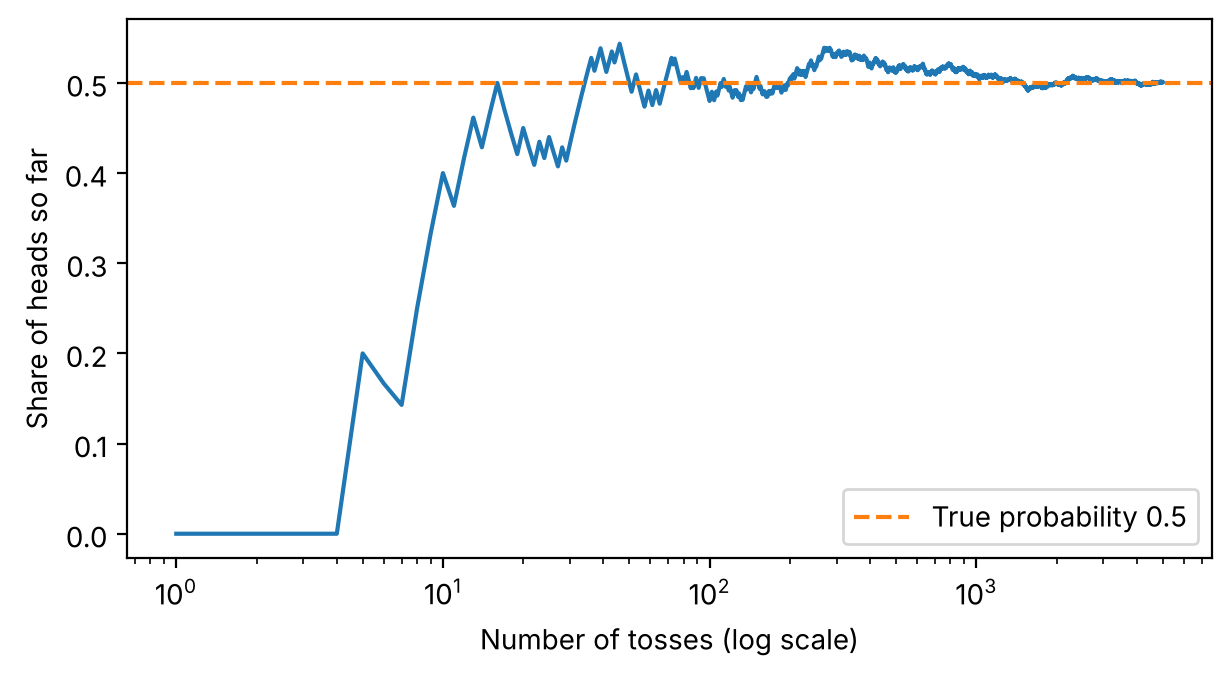

After 10 tosses: 0.40 | after 100: 0.48 | after 5,000: 0.501


In [3]:
# Step 3. Law of large numbers: the running share of heads settles near 0.5
import matplotlib.pyplot as plt

tosses = rng.integers(0, 2, size=5_000)
running = tosses.cumsum() / np.arange(1, 5_001)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, 5_001), running, color="tab:blue")
ax.axhline(0.5, color="tab:orange", ls="--", label="True probability 0.5")
ax.set_xscale("log")
ax.set_xlabel("Number of tosses (log scale)")
ax.set_ylabel("Share of heads so far")
ax.legend()
plt.show()
print(f"After 10 tosses: {running[9]:.2f} | after 100: {running[99]:.2f} | after 5,000: {running[-1]:.3f}")

In [4]:
# Step 4. Roll a die 60,000 times: each face should appear about 1/6 of the time
rolls = rng.integers(1, 7, size=60_000)
freq = pd.Series(rolls).value_counts().sort_index()
print(pd.DataFrame({"count": freq, "share": (freq / len(rolls)).round(4)}).to_string())
print(f"Theory: 1/6 = {1/6:.4f}")

   count   share
1  10038  0.1673
2  10023  0.1670
3   9999  0.1666
4   9941  0.1657
5   9997  0.1666
6  10002  0.1667
Theory: 1/6 = 0.1667


In [5]:
# Step 5. Simulate customers: 1,257 visitors a day, each buys with probability 0.64
visitors, p_buy = 1257, 0.64
buys = rng.random(visitors) < p_buy              # True if this visitor buys
print("Buyers on one simulated day:", buys.sum(), f"(expected {visitors * p_buy:.0f})")
days = rng.binomial(n=visitors, p=p_buy, size=731)   # 731 simulated days in one line
print(f"Over 731 simulated days: mean buyers {days.mean():.1f}, SD {days.std(ddof=1):.1f}")

Buyers on one simulated day: 816 (expected 804)
Over 731 simulated days: mean buyers 805.4, SD 16.9


In [6]:
# Step 6. Compare with the real S05 store: does real conversion vary more than chance alone?
url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
s05 = df[df["store_id"] == "S05"]
real_conv = s05["transactions"] / s05["footfall"]
sim_conv = days / visitors
print(f"Real S05 conversion : mean {real_conv.mean():.3f}, SD {real_conv.std():.4f}")
print(f"Simulated conversion: mean {sim_conv.mean():.3f}, SD {sim_conv.std(ddof=1):.4f}")

Real S05 conversion : mean 0.635, SD 0.0393
Simulated conversion: mean 0.641, SD 0.0134
